# Blackjack Monte Carlo — Analysis

This notebook drives the Java engine in this repository and analyses its output. It answers five questions:

1. **Is the engine correct?** Basic strategy should reproduce the published house edge for these rules.
2. **How much does playing strategy matter?** From optimal basic strategy to always hitting.
3. **Can card counting beat the game?** Player expectation as a function of the Hi-Lo true count, and what a 1–12 bet spread does with it.
4. **Do betting systems work?** Martingale, Oscar's Grind and 1-3-2-6 against flat betting, including risk of ruin.
5. **Which table rules matter?** Number of decks, H17, 6:5 payouts, doubling after splits and surrender.

**Default rules:** 6 decks, dealer stands on soft 17, blackjack pays 3:2, double on any two cards, double after split, late surrender, split up to 4 hands, split aces get one card, dealer peeks, reshuffle at 75 % penetration.

**Definitions.** *House edge* is minus the mean of `net / initial bet` per round, the standard figure quoted for a game. *Player return* is `total net / total amount bet`, which is what bet sizing can change. All intervals are 95 % (±1.96 standard errors).

> To reproduce from scratch: delete `results/` and run all cells. The engine is compiled and run from here (Java 21+ required). With 2 CPU cores the full set of simulations takes a few minutes.

In [1]:
import subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = ROOT / "results"
FIGURES = ROOT / "docs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

# Categorical palette (fixed order) and neutral inks
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, INK2, GRID = "#0b0b0b", "#52514e", "#e4e3df"

plt.rcParams.update({
    "figure.figsize": (10, 5.5), "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "axes.titleweight": "bold", "axes.titlesize": 13,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "xtick.color": INK2, "ytick.color": INK2, "legend.frameon": False, "lines.linewidth": 2,
})
pct = mtick.PercentFormatter(1.0, decimals=1)

def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png")

## 1. Run the simulations

`simulate()` calls the engine's command-line interface and skips any experiment whose results already exist. Each experiment writes `summary.csv`, `outcomes.csv`, `count_edge.csv` and per-session files to its own folder. Every run uses a fixed seed, so the numbers below are exactly reproducible.

In [2]:
def build():
    sources = [str(p.relative_to(ROOT)) for p in (ROOT / "src").rglob("*.java")]
    run = subprocess.run(["javac", "--release", "21", "-d", "bin", *sources], cwd=ROOT, capture_output=True, text=True)
    if run.returncode != 0:
        raise RuntimeError(run.stderr)

def simulate(name, *args):
    out = RESULTS / name
    if (out / "summary.csv").exists():
        return out
    cmd = ["java", "-cp", "bin", "Main", *args, "--out", str(out.relative_to(ROOT))]
    run = subprocess.run(cmd, cwd=ROOT, check=True, capture_output=True, text=True)
    print("\n".join(l for l in run.stdout.splitlines() if not l.startswith("CSV files")))
    return out

build()

# Every playing strategy with flat bets + basic strategy with every betting system
simulate("suite", "suite", "--sims", "1000", "--hands", "10000")
# High-precision runs for validation and card counting (100 M hands each)
simulate("precision", "simulate", "--play", "basic", "--bet", "flat,hilo", "--sims", "4000", "--hands", "25000", "--sample-every", "250")
# Risk of ruin: 100-unit bankroll, 5,000 hands
simulate("ruin", "simulate", "--play", "basic", "--bet", "flat,martingale,oscar,1326,hilo",
         "--sims", "5000", "--hands", "5000", "--bankroll", "100", "--sample-every", "50")
# Number of decks
for d in [1, 2, 4, 6, 8]:
    simulate(f"decks/{d}", "simulate", "--decks", str(d), "--sims", "2000", "--hands", "20000")
# Rule variations
for name, flags in {"baseline": [], "h17": ["--h17"], "no-das": ["--no-das"],
                    "no-surrender": ["--no-surrender"], "six-five": ["--six-five"]}.items():
    simulate(f"rules/{name}", "simulate", "--sims", "2000", "--hands", "20000", *flags)
# Hi-Lo with different penetrations
for pen in ["0.5", "0.65", "0.75", "0.85"]:
    simulate(f"penetration/{pen}", "simulate", "--bet", "hilo", "--penetration", pen, "--sims", "2000", "--hands", "20000")
print("All simulations available.")

All simulations available.


## 2. Validation: does basic strategy match the theory?

Published simulations put the house edge of a six-deck S17, DAS, 3:2 game **without surrender** at about **0.44 %**, and late surrender is worth about **0.07–0.08** percentage points in multi-deck games, so these rules should give roughly **0.36–0.37 %**. With 100 million simulated hands the estimate should land within a few hundredths of a point of it; the no-surrender variant is checked against 0.44 % in section 6.

In [3]:
precision = pd.read_csv(RESULTS / "precision" / "summary.csv")
basic = precision.query("betting == 'Flat'").iloc[0]
lo, hi = basic.house_edge - 1.96 * basic.house_edge_se, basic.house_edge + 1.96 * basic.house_edge_se
print(f"Hands simulated:      {basic.rounds:,.0f}")
print(f"House edge:           {basic.house_edge:.3%}  (95% CI {lo:.3%} to {hi:.3%})")
print(f"Published reference:  ~0.36-0.37% (0.44% without surrender)")
print(f"Win / loss / push:    {basic.win_rate:.2%} / {basic.loss_rate:.2%} / {basic.push_rate:.2%}")
print(f"Blackjacks / doubles / splits / surrenders per 100 hands: "
      f"{100*basic.player_blackjack_rate:.2f} / {100*basic.double_rate:.2f} / {100*basic.split_rate:.2f} / {100*basic.surrender_rate:.2f}")
print(f"Std. deviation per hand: {basic.sd_per_round_units:.3f} units")

Hands simulated:      100,000,000
House edge:           0.371%  (95% CI 0.349% to 0.394%)
Published reference:  ~0.36-0.37% (0.44% without surrender)
Win / loss / push:    42.40% / 49.11% / 8.49%
Blackjacks / doubles / splits / surrenders per 100 hands: 4.74 / 10.40 / 2.79 / 4.47
Std. deviation per hand: 1.141 units


The player wins fewer hands than they lose (≈ 42 % vs 49 %) and still almost breaks even: blackjacks pay 3:2, doubles win twice the bet in favourable spots, and surrender halves losses on the worst hands. The table below shows where each round ends up.

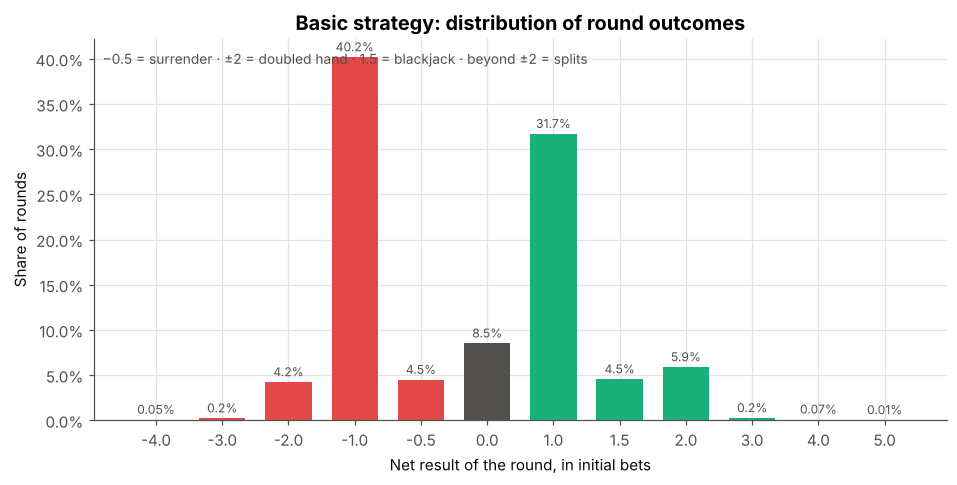

In [4]:
out = pd.read_csv(RESULTS / "precision" / "outcomes.csv").query("betting == 'Flat'")
out["share"] = out.rounds / out.rounds.sum()
out = out[out.share > 1e-4]

fig, ax = plt.subplots(figsize=(10, 4.5))
colors = [C[7] if x < 0 else (C[2] if x > 0 else INK2) for x in out.net_per_bet]
ax.bar(out.net_per_bet.astype(str), out.share, color=colors, width=0.7)
for x, y in zip(out.net_per_bet.astype(str), out.share):
    ax.annotate(f"{y:.1%}" if y >= 0.001 else f"{y:.2%}", (x, y), ha="center", va="bottom", fontsize=8, color=INK2,
                xytext=(0, 2), textcoords="offset points")
ax.yaxis.set_major_formatter(pct)
ax.set_xlabel("Net result of the round, in initial bets")
ax.set_ylabel("Share of rounds")
ax.set_title("Basic strategy: distribution of round outcomes")
ax.text(0.01, 0.97, "−0.5 = surrender · ±2 = doubled hand · 1.5 = blackjack · beyond ±2 = splits",
        transform=ax.transAxes, va="top", fontsize=9, color=INK2)
save(fig, "outcome_distribution")
plt.show()

## 3. How much does playing strategy matter?

All strategies below bet one unit per hand. The engine also includes four naive baselines: *Threshold17* hits below 17 like the dealer, *Random* hits or stands with equal probability, and *OnlyHit* / *OnlyStand* never vary.

In [5]:
suite = pd.read_csv(RESULTS / "suite" / "summary.csv")
flat = suite.query("betting == 'Flat'").sort_values("house_edge").reset_index(drop=True)

table = flat[["playing", "win_rate", "loss_rate", "push_rate", "house_edge", "house_edge_se"]].copy()
table["house_edge_ci"] = 1.96 * table.pop("house_edge_se")
table.style.format({"win_rate": "{:.2%}", "loss_rate": "{:.2%}", "push_rate": "{:.2%}",
                    "house_edge": "{:.2%}", "house_edge_ci": "±{:.2%}"}).hide(axis="index")

playing,win_rate,loss_rate,push_rate,house_edge,house_edge_ci
BasicStrategy,42.40%,49.11%,8.48%,0.37%,±0.07%
Threshold17,41.15%,49.09%,9.76%,5.68%,±0.06%
OnlyStand,38.46%,56.72%,4.82%,15.99%,±0.06%
Random,31.88%,63.99%,4.12%,29.84%,±0.06%
OnlyHit,16.08%,82.74%,1.17%,64.40%,±0.05%


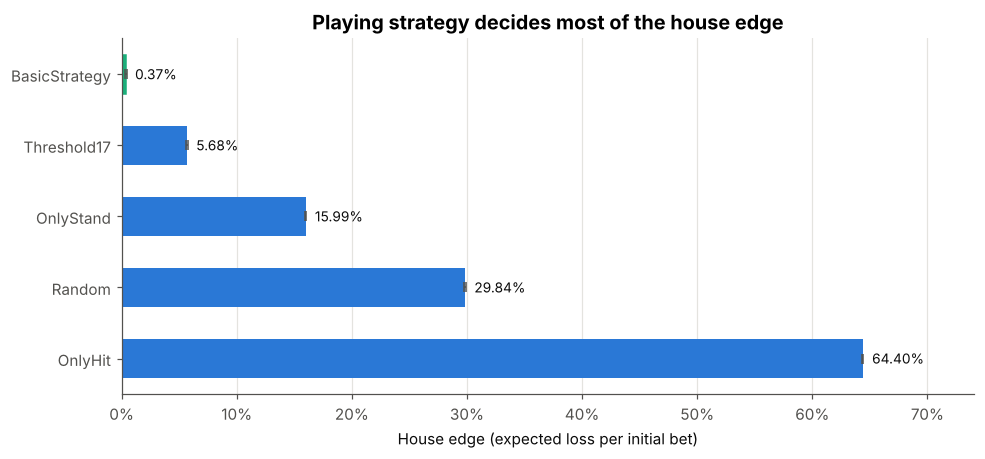

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.2))
y = np.arange(len(flat))[::-1]
bars = ax.barh(y, flat.house_edge, xerr=1.96 * flat.house_edge_se, color=C[0], height=0.55,
               error_kw=dict(ecolor=INK2, capsize=3, lw=1))
bars[0].set_color(C[2])
ax.set_yticks(y, flat.playing)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
for yi, v in zip(y, flat.house_edge):
    ax.annotate(f"{v:.2%}", (v, yi), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9, color=INK)
ax.set_xlim(0, flat.house_edge.max() * 1.15)
ax.set_xlabel("House edge (expected loss per initial bet)")
ax.set_title("Playing strategy decides most of the house edge")
ax.grid(axis="y", visible=False)
save(fig, "house_edge_by_strategy")
plt.show()

Playing like the dealer already costs more than ten times what basic strategy does: the dealer's advantage comes from the player acting first and busting first, and the 3:2 payout, doubling, splitting and surrender are the player's only ways to claw that back.

### How the edge plays out over a session

The house edge is an average. Over a 10,000-hand session (several months of regular play) the spread between lucky and unlucky players is still much larger than the expected loss for basic strategy, while bad strategies drown any luck.

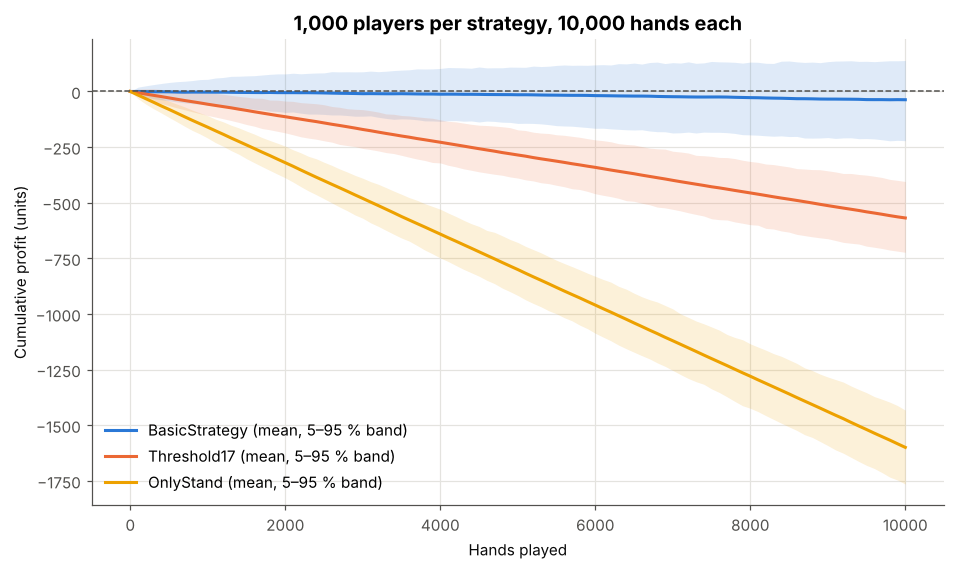

In [7]:
def load_traj(folder, play, bet):
    return pd.read_csv(RESULTS / folder / "trajectories" / f"{play}__{bet}.csv", index_col="session")

fig, ax = plt.subplots(figsize=(10, 5.5))
for (play, color) in [("BasicStrategy", C[0]), ("Threshold17", C[1]), ("OnlyStand", C[3])]:
    t = load_traj("suite", play, "Flat")
    hands = t.columns.astype(int)
    p5, p50, p95 = t.quantile([0.05, 0.5, 0.95]).values
    ax.fill_between(hands, p5, p95, color=color, alpha=0.15, lw=0)
    ax.plot(hands, t.mean(), color=color, label=f"{play} (mean, 5–95 % band)")
ax.axhline(0, color=INK2, lw=1, ls="--")
ax.set_xlabel("Hands played")
ax.set_ylabel("Cumulative profit (units)")
ax.set_title("1,000 players per strategy, 10,000 hands each")
ax.legend(loc="lower left")
save(fig, "trajectories_by_strategy")
plt.show()

Players ahead after 10,000 hands: 38.6%


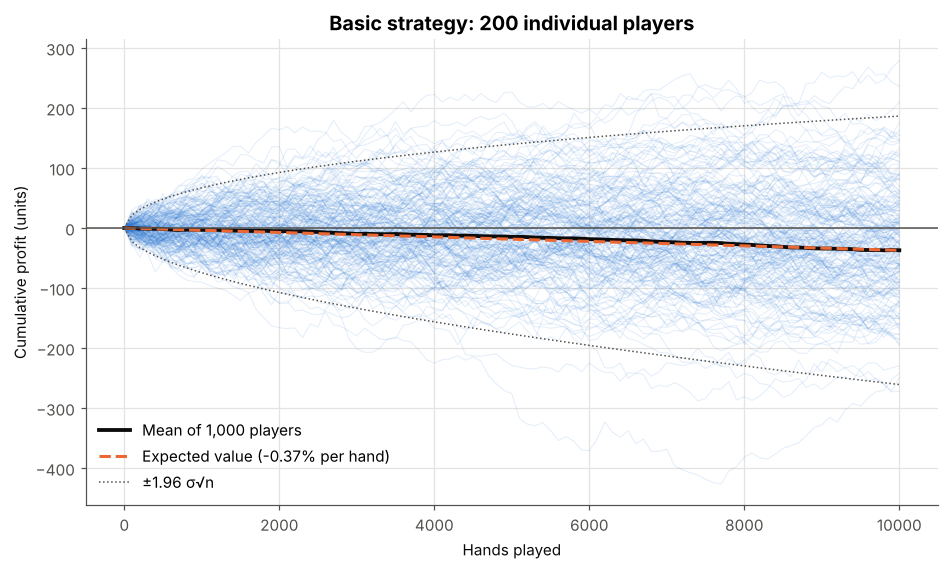

In [8]:
t = load_traj("suite", "BasicStrategy", "Flat")
hands = t.columns.astype(int)
fig, ax = plt.subplots(figsize=(10, 5.5))
for _, row in t.iloc[:200].iterrows():
    ax.plot(hands, row.values, color=C[0], alpha=0.12, lw=0.7)
ax.plot(hands, t.mean(), color=INK, lw=2.5, label="Mean of 1,000 players")
expected = -basic.house_edge * hands
ax.plot(hands, expected, color=C[1], lw=2, ls="--", label=f"Expected value ({-basic.house_edge:.2%} per hand)")
sd = basic.sd_per_round_units * np.sqrt(hands)
ax.plot(hands, expected + 1.96 * sd, color=INK2, lw=1, ls=":", label="±1.96 σ√n")
ax.plot(hands, expected - 1.96 * sd, color=INK2, lw=1, ls=":")
ax.axhline(0, color=INK2, lw=1)
ax.set_xlabel("Hands played")
ax.set_ylabel("Cumulative profit (units)")
ax.set_title("Basic strategy: 200 individual players")
ax.legend(loc="lower left")
final = t.iloc[:, -1]
print(f"Players ahead after 10,000 hands: {(final > 0).mean():.1%}")
save(fig, "basic_strategy_paths")
plt.show()

Roughly four in ten basic-strategy players are still ahead after 10,000 hands. The ±1.96σ√n envelope (σ ≈ 1.15 units per hand) predicts the spread almost exactly: variance grows with √n while the expected loss grows with n, so the house only "wins" reliably in the very long run.

## 4. Card counting

The Hi-Lo count adds +1 for every 2–6 seen and −1 for every ten or ace. Divided by the decks left in the shoe it gives the **true count**. When the count is high, the remaining cards are rich in tens and aces: more blackjacks for the player, more dealer busts and better doubles.

The engine records the true count before every hand, so we can measure the player's expectation at each count directly, with the same basic strategy and flat bets.

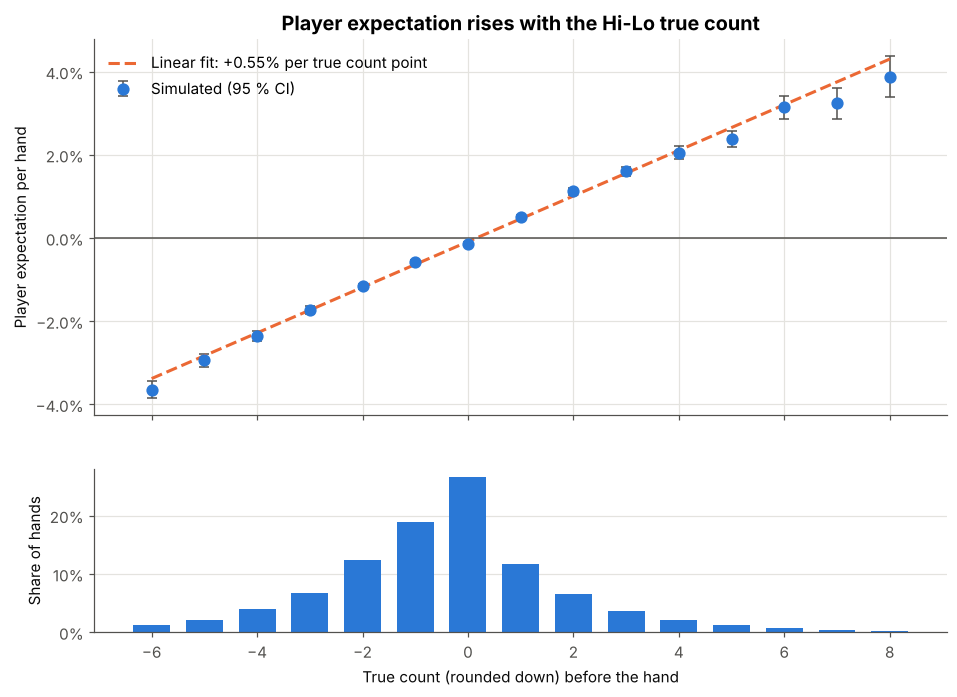

Edge gained per true count point: 0.549%; break-even true count ≈ 0.2
Hands played at a true count of +2 or more: 14.6%


In [9]:
ce = pd.read_csv(RESULTS / "precision" / "count_edge.csv").query("betting == 'Flat' and -6 <= true_count <= 8")
share = ce.rounds / pd.read_csv(RESULTS / "precision" / "count_edge.csv").query("betting == 'Flat'").rounds.sum()

fit = np.polyfit(ce.true_count, ce.player_return, 1, w=1 / ce.player_return_se)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1.3]})
ax1.errorbar(ce.true_count, ce.player_return, yerr=1.96 * ce.player_return_se, fmt="o", color=C[0],
             ms=7, capsize=3, ecolor=INK2, elinewidth=1, label="Simulated (95 % CI)")
xs = np.linspace(-6, 8, 50)
ax1.plot(xs, np.polyval(fit, xs), color=C[1], lw=2, ls="--",
         label=f"Linear fit: {fit[0]:+.2%} per true count point")
ax1.axhline(0, color=INK2, lw=1)
ax1.yaxis.set_major_formatter(pct)
ax1.set_ylabel("Player expectation per hand")
ax1.set_title("Player expectation rises with the Hi-Lo true count")
ax1.legend(loc="upper left")
ax2.bar(ce.true_count, share, color=C[0], width=0.7)
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax2.set_ylabel("Share of hands")
ax2.set_xlabel("True count (rounded down) before the hand")
ax2.grid(axis="x", visible=False)
save(fig, "edge_vs_true_count")
plt.show()
breakeven = -fit[1] / fit[0]
print(f"Edge gained per true count point: {fit[0]:.3%}; break-even true count ≈ {breakeven:.1f}")
print(f"Hands played at a true count of +2 or more: {share[ce.true_count >= 2].sum():.1%}")

The player has the edge in only a small fraction of hands. Counting pays by **betting more exactly in those hands**: the Hi-Lo bettor here bets `true count − 1` units (between 1 and 12). Bet sizing does not change the expectation of any single hand, so the house edge per hand is identical for both players; what changes is the return on the money wagered.

Flat      player return -0.371% ± 0.022%   mean bet 1.00 u   EV -0.0037 u/hand   SD 1.14 u/hand
HiLo1-12  player return +0.092% ± 0.026%   mean bet 1.18 u   EV +0.0011 u/hand   SD 1.58 u/hand
Hi-Lo players ahead after 25,000 hands: 54.1%


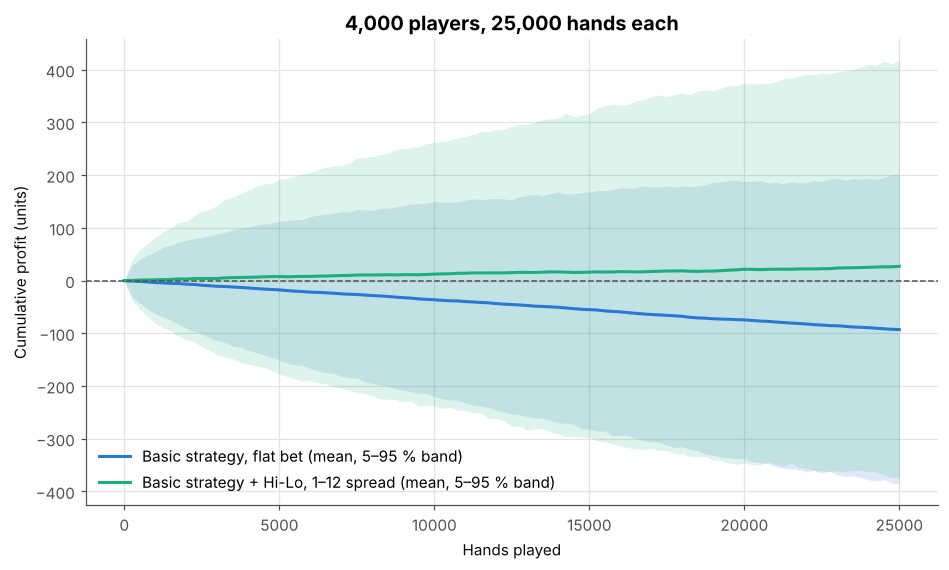

In [10]:
cmp = precision.set_index("betting")
for b in ["Flat", "HiLo1-12"]:
    r = cmp.loc[b]
    print(f"{b:9s} player return {r.player_return:+.3%} ± {1.96*r.player_return_se:.3%}   "
          f"mean bet {r.mean_bet_units:.2f} u   EV {r.ev_per_round_units:+.4f} u/hand   SD {r.sd_per_round_units:.2f} u/hand")

hilo = cmp.loc["HiLo1-12"]
fig, ax = plt.subplots(figsize=(10, 5.5))
for bet, color, label in [("Flat", C[0], "Basic strategy, flat bet"), ("HiLo1-12", C[2], "Basic strategy + Hi-Lo, 1–12 spread")]:
    t = load_traj("precision", "BasicStrategy", bet)
    hands = t.columns.astype(int)
    p5, p95 = t.quantile([0.05, 0.95]).values
    ax.fill_between(hands, p5, p95, color=color, alpha=0.15, lw=0)
    ax.plot(hands, t.mean(), color=color, label=label + " (mean, 5–95 % band)")
ax.axhline(0, color=INK2, lw=1, ls="--")
ax.set_xlabel("Hands played")
ax.set_ylabel("Cumulative profit (units)")
ax.set_title("4,000 players, 25,000 hands each")
ax.legend(loc="lower left")
print(f"Hi-Lo players ahead after 25,000 hands: {(load_traj('precision','BasicStrategy','HiLo1-12').iloc[:, -1] > 0).mean():.1%}")
save(fig, "hilo_vs_flat")
plt.show()

The counter turns a small loss into a small **positive** return, but the advantage is thin and the variance is several times larger, so even after 25,000 hands a sizeable share of counters is still behind. The edge also depends on how deep the dealer deals before reshuffling: counts only become extreme near the end of the shoe.

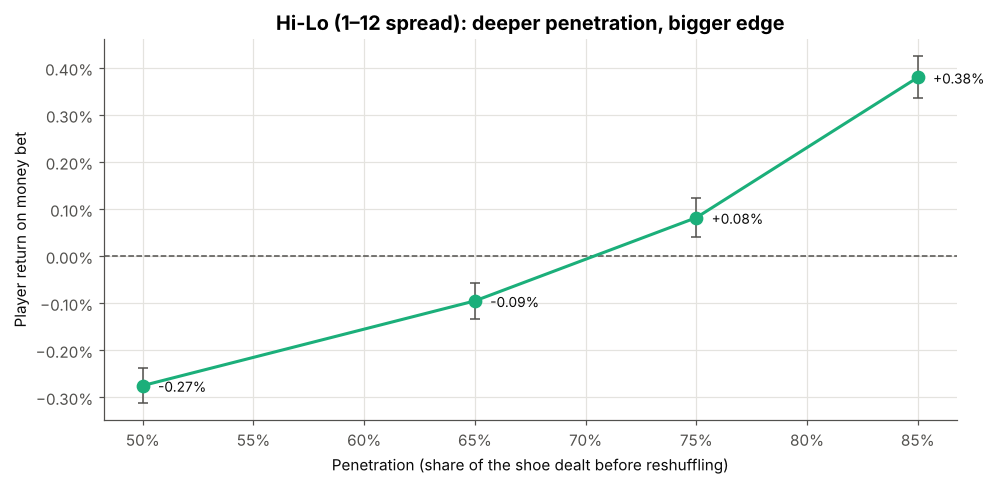

In [11]:
rows = []
for pen in ["0.5", "0.65", "0.75", "0.85"]:
    s = pd.read_csv(RESULTS / "penetration" / pen / "summary.csv").iloc[0]
    rows.append((float(pen), s.player_return, s.player_return_se))
pen_df = pd.DataFrame(rows, columns=["penetration", "ret", "se"])

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.errorbar(pen_df.penetration, pen_df.ret, yerr=1.96 * pen_df.se, fmt="o-", color=C[2], ms=8,
            capsize=3, ecolor=INK2, elinewidth=1)
for x, v in zip(pen_df.penetration, pen_df.ret):
    ax.annotate(f"{v:+.2%}", (x, v), xytext=(10, -4), textcoords="offset points", fontsize=9, color=INK)
ax.axhline(0, color=INK2, lw=1, ls="--")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=2))
ax.set_xlabel("Penetration (share of the shoe dealt before reshuffling)")
ax.set_ylabel("Player return on money bet")
ax.set_title("Hi-Lo (1–12 spread): deeper penetration, bigger edge")
save(fig, "hilo_penetration")
plt.show()

## 5. Betting systems

Progressions change *how much* is bet after wins and losses, but every hand is still played at a negative expectation. The table compares them with basic strategy over 10,000 hands and an unlimited bankroll (table maximum 500 units).

In [12]:
systems = suite.query("playing == 'BasicStrategy'").copy()
systems = systems[["betting", "house_edge", "player_return", "player_return_se", "mean_bet_units",
                   "sd_per_round_units", "mean_max_drawdown_units"]]
systems["player_return_ci"] = 1.96 * systems.pop("player_return_se")
systems.style.format({"house_edge": "{:.2%}", "player_return": "{:+.2%}", "player_return_ci": "±{:.2%}",
                      "mean_bet_units": "{:.2f}", "sd_per_round_units": "{:.2f}",
                      "mean_max_drawdown_units": "{:.0f}"}).hide(axis="index")

betting,house_edge,player_return,mean_bet_units,sd_per_round_units,mean_max_drawdown_units,player_return_ci
Flat,0.37%,-0.37%,1.00,1.14,157,±0.07%
HiLo1-12,0.37%,+0.11%,1.18,1.58,189,±0.08%
Martingale,0.37%,-0.48%,7.48,41.39,5267,±0.34%
OscarsGrind,0.37%,-0.54%,33.31,120.87,9647,±0.22%
1-3-2-6,0.37%,-0.39%,1.92,2.65,361,±0.09%


Every progression lands on the same return on money bet as flat betting, within the margin of error, except Hi-Lo, which is the only system that uses information about the cards. Progressions only reshape the *distribution* of outcomes. That shows up when the bankroll is finite: below, every player starts with **100 units** and plays up to 5,000 hands, stopping if they can no longer cover the minimum bet.

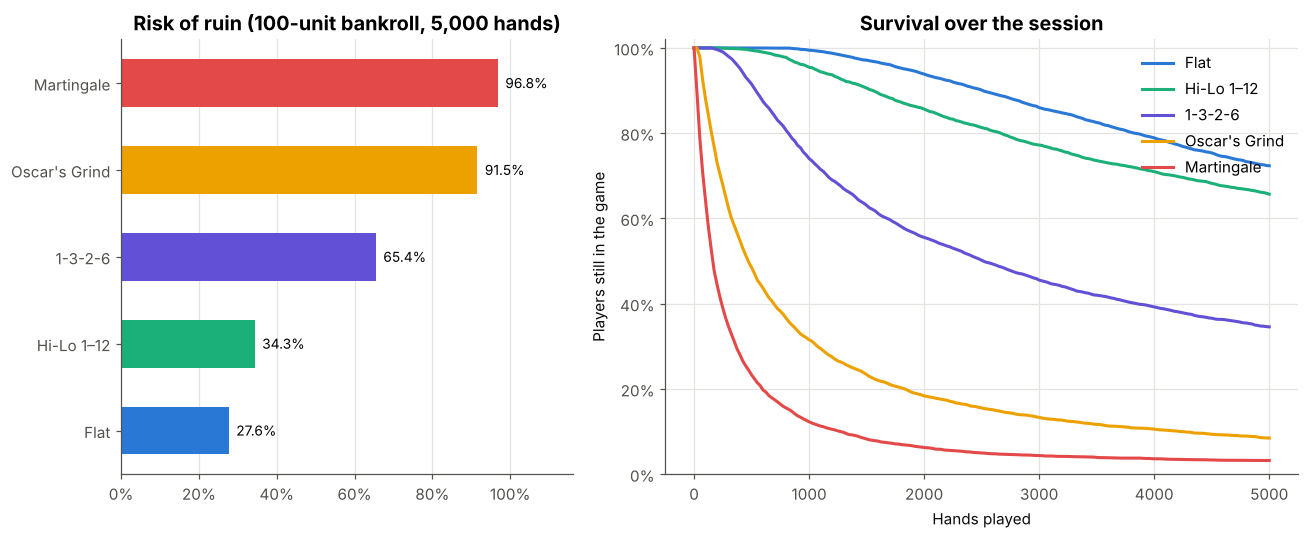

In [13]:
ruin = pd.read_csv(RESULTS / "ruin" / "summary.csv")
names = {"Flat": "Flat", "Martingale": "Martingale", "OscarsGrind": "Oscar's Grind", "1-3-2-6": "1-3-2-6", "HiLo1-12": "Hi-Lo 1–12"}
colors = {"Flat": C[0], "Martingale": C[7], "OscarsGrind": C[3], "1-3-2-6": C[6], "HiLo1-12": C[2]}

fig, axes = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [1, 1.4]})
ax = axes[0]
order = ruin.sort_values("ruin_rate")
ax.barh(order.betting.map(names), order.ruin_rate, color=[colors[b] for b in order.betting], height=0.55)
for i, v in enumerate(order.ruin_rate):
    ax.annotate(f"{v:.1%}", (v, i), xytext=(5, 0), textcoords="offset points", va="center", fontsize=9)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xlim(0, max(order.ruin_rate) * 1.2)
ax.set_title("Risk of ruin (100-unit bankroll, 5,000 hands)")
ax.grid(axis="y", visible=False)

ax = axes[1]
grid = np.arange(0, 5001, 25)
for b in ["Flat", "HiLo1-12", "1-3-2-6", "OscarsGrind", "Martingale"]:
    s = pd.read_csv(RESULTS / "ruin" / "sessions" / f"BasicStrategy__{b}.csv")
    busted_at = s.hands_played.where(s.ruined == 1, np.inf).values
    alive = [(busted_at > g).mean() for g in grid]
    ax.plot(grid, alive, color=colors[b], label=names[b])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_ylim(0, 1.02)
ax.set_xlabel("Hands played")
ax.set_ylabel("Players still in the game")
ax.set_title("Survival over the session")
ax.legend(loc="upper right")
fig.tight_layout()
save(fig, "betting_systems_ruin")
plt.show()

In [14]:
mart = pd.read_csv(RESULTS / "ruin" / "sessions" / "BasicStrategy__Martingale.csv")
print(f"Martingale: {mart.ruined.mean():.1%} of players lose the whole bankroll; median hands before ruin: "
      f"{mart.loc[mart.ruined == 1, 'hands_played'].median():,.0f}")

Martingale: 96.8% of players lose the whole bankroll; median hands before ruin: 156


The Martingale wins one unit almost every time a losing streak ends, so it feels like a steady earner, but with 100 units a run of seven losses in a row (which needs 127 units) ends the session, and such runs show up every few hundred hands. Oscar's Grind fails more slowly for the same reason. The progressions do not lose *more on average per unit bet*; they concentrate the losses into ruin. Card counting also needs a much larger bankroll than 100 units: its positive edge comes with higher variance, so it busts more often than flat betting at this bankroll size.

## 6. Table rules

The same basic-strategy player, changing one rule at a time against the baseline (6 decks, S17, DAS, late surrender, 3:2), and then the number of decks.

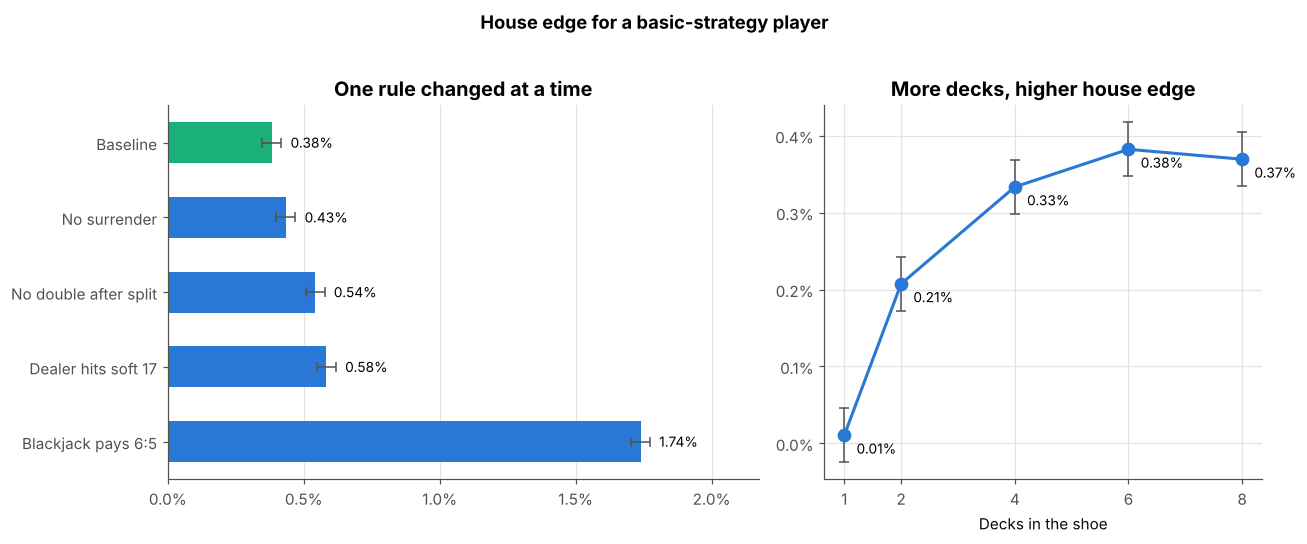

In [15]:
labels = {"baseline": "Baseline", "h17": "Dealer hits soft 17", "no-das": "No double after split",
          "no-surrender": "No surrender", "six-five": "Blackjack pays 6:5"}
rules = pd.concat([pd.read_csv(RESULTS / "rules" / k / "summary.csv").assign(rule=v) for k, v in labels.items()])
decks = pd.concat([pd.read_csv(RESULTS / "decks" / str(d) / "summary.csv") for d in [1, 2, 4, 6, 8]])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), gridspec_kw={"width_ratios": [1.35, 1]})
ax = axes[0]
r = rules.sort_values("house_edge")
y = np.arange(len(r))[::-1]
ax.barh(y, r.house_edge, xerr=1.96 * r.house_edge_se, height=0.55,
        color=[C[0] if x != "Baseline" else C[2] for x in r.rule], error_kw=dict(ecolor=INK2, capsize=3, lw=1))
ax.set_yticks(y, r.rule)
for yi, v, se in zip(y, r.house_edge, r.house_edge_se):
    ax.annotate(f"{v:.2%}", (v + 1.96 * se, yi), xytext=(6, 0), textcoords="offset points", va="center", fontsize=9)
ax.xaxis.set_major_locator(mtick.MultipleLocator(0.005))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=1))
ax.set_xlim(0, r.house_edge.max() * 1.25)
ax.set_title("One rule changed at a time")
ax.grid(axis="y", visible=False)

ax = axes[1]
ax.errorbar(decks.decks, decks.house_edge, yerr=1.96 * decks.house_edge_se, fmt="o-", color=C[0],
            ms=8, capsize=3, ecolor=INK2, elinewidth=1)
for x, v in zip(decks.decks, decks.house_edge):
    ax.annotate(f"{v:.2%}", (x, v), xytext=(8, -12), textcoords="offset points", fontsize=9)
ax.set_xticks([1, 2, 4, 6, 8])
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=1))
ax.set_xlabel("Decks in the shoe")
ax.set_title("More decks, higher house edge")
fig.suptitle("House edge for a basic-strategy player", fontweight="bold", y=1.02)
fig.tight_layout()
save(fig, "rules_and_decks")
plt.show()

The 6:5 payout is by far the most expensive rule change, more than all the others together, and the no-surrender game lands on the published 0.44 %. Fewer decks clearly help up to four decks; between six and eight the difference (≈ 0.02 points in theory) is smaller than the simulation noise. The deck-count curve uses the multi-deck basic strategy chart for every shoe size; a single-deck–specific chart would gain a little more.

## 7. Conclusions

* The engine reproduces the published house edge for its rules (0.37 % here, 0.44 % without surrender), which validates the game logic (dealer peek, splits, doubles, surrender) and the basic strategy tables.
* **Playing strategy dominates**: basic strategy loses ≈ 0.37 % per hand; playing like the dealer loses more than ten times as much.
* **Bet sizing only helps when it uses information.** Hi-Lo counting with a 1–12 spread turns the game slightly positive, and the gain grows with penetration. Martingale, Oscar's Grind and 1-3-2-6 leave the return unchanged and only reshape risk; the Martingale in particular trades frequent small wins for a high risk of ruin.
* **Rules matter as much as skill:** a 6:5 payout costs more than all other rule changes combined.

Limitations: basic strategy is total-dependent (no composition-dependent plays), the counter uses no index plays or insurance, and hands within a shoe are correlated, so the reported standard errors are slightly optimistic.